# Connection plasticity: pair STDP

A `connect` call can carry a plasticity rule. The rule then changes the weight of
every row of that call while the model runs; `ConnectionView.rule_state("w")`
reads the current weight. This tutorial uses the built-in rule,
`braincell.plasticity.PairSTDP`, all-to-all pair spike-timing-dependent
plasticity with additive updates.

Read [Connection](connection.ipynb) first: a rule is declared on the same
`connect` call that routes the events.

Sections 5 and 6 turn to short-term depression and facilitation, which live in
the synapse rather than on the connection: `braincell.synapse.ExpSynSTD` and
`braincell.synapse.ExpSynSTP`.

In [1]:
import os

os.environ.setdefault("JAX_PLATFORMS", "cpu")

import brainstate
import brainunit as u
import matplotlib.pyplot as plt
import numpy as np

import braincell
from braincell import mech

brainstate.environ.set(precision=64)

## 1. Declaring a rule

`mech.ConnectionRule` names a rule and its parameters, as `mech.Synapse` names a
synapse model. Every row of a pair rule keeps a presynaptic trace $x$ and a
postsynaptic trace $y$, which decay with $\tau_+$ and $\tau_-$. At an event
boundary where a row has $n_\mathrm{pre}$ arrivals and its target member
$n_\mathrm{post}$ spikes, the rule reads the state just before the boundary:

$$w \leftarrow w + A_+\, x\, n_\mathrm{post} - A_-\, y\, n_\mathrm{pre},\qquad
x \leftarrow x + n_\mathrm{pre},\qquad y \leftarrow y + n_\mathrm{post}.$$

So a pre event $\Delta t$ before a post event adds $A_+ e^{-\Delta t/\tau_+}$, a
post event $\Delta t$ before a pre event subtracts $A_- e^{-\Delta t/\tau_-}$,
and a pre and a post event on the same boundary do not pair.

The `post` events default to the target Cell's own spikes. Here a scheduled
source stands in for them as a teaching signal, so that the point neuron needs
no channels: a pre event at 0 ms and a post event at 10 ms.

In [2]:
cell = braincell.Cell.point(1, V_init=-65.0 * u.mV)
cell.place(mech.Synapse("ExpSyn", name="s", tau=2.0 * u.ms, e=0.0 * u.mV))

stdp = mech.ConnectionRule(
    "PairSTDP",
    A_plus=0.01 * u.uS,
    A_minus=0.0105 * u.uS,
    tau_plus=20.0 * u.ms,
    tau_minus=20.0 * u.ms,
    signals={"post": braincell.EventSequence.from_times(([10.0] * u.ms,))},
)
braincell.connect(
    "c",
    source=braincell.EventSequence.from_times(([0.0] * u.ms,)),
    synapse=cell.synapses["s"],
    weight=0.05 * u.uS,
    plasticity=stdp,
)
cell.run(dt=0.1 * u.ms, duration=12.0 * u.ms)

dw = cell.connections["c"].rule_state("w") - 0.05 * u.uS
print("simulated:", dw)
print("reference:", 0.01 * np.exp(-10.0 / 20.0) * u.uS)

simulated: [0.00606531] uS
reference: 0.00606531 uS


`rule_state` also reads the traces, `"x_pre"` and `"y_post"`. The event a row
delivers at a boundary carries the weight *before* that boundary's update, so
the synapse here received 0.05 uS at 0 ms.

In [3]:
print("x_pre :", cell.connections["c"].rule_state("x_pre"))
print("y_post:", cell.connections["c"].rule_state("y_post"))

x_pre : [0.55156257]
y_post: [0.90937293]


## 2. The STDP window in one run

Each row has its own state, so one Cell population can measure the whole window
at once: member $i$ gets a pre event at 60 ms and a post event at
$60 + \Delta t_i$ ms. The rule's parameters may also be one value per row; here
they are shared.

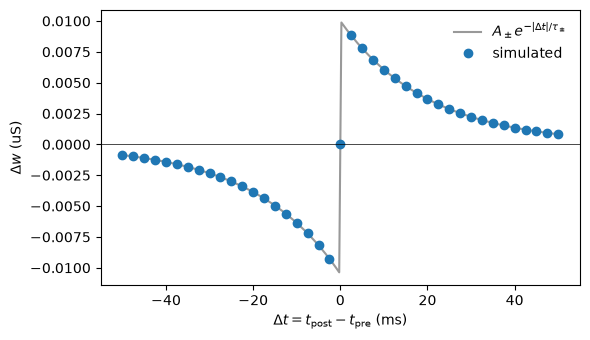

In [4]:
lags = np.arange(-50.0, 50.1, 2.5)
n = lags.size

window_cell = braincell.Cell.point(n, V_init=-65.0 * u.mV)
window_cell.place(mech.Synapse("ExpSyn", name="s", tau=2.0 * u.ms, e=0.0 * u.mV))
pre = braincell.EventSequence.from_times(tuple([60.0] * u.ms for _ in range(n)))
post = braincell.EventSequence.from_times(tuple([60.0 + lag] * u.ms for lag in lags))
rule = mech.ConnectionRule(
    "PairSTDP",
    A_plus=0.01 * u.uS,
    A_minus=0.0105 * u.uS,
    tau_plus=20.0 * u.ms,
    tau_minus=20.0 * u.ms,
    signals={"post": post},
)
braincell.connect("c", source=pre, synapse=window_cell.synapses["s"], weight=0.05 * u.uS, plasticity=rule)
window_cell.run(dt=0.1 * u.ms, duration=120.0 * u.ms)
dw = (window_cell.connections["c"].rule_state("w") - 0.05 * u.uS).to_decimal(u.uS)

dense = np.linspace(-50.0, 50.0, 401)
reference = np.where(dense > 0, 0.01 * np.exp(-dense / 20.0), -0.0105 * np.exp(dense / 20.0))
reference[dense == 0] = 0.0

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.plot(dense, reference, color="0.6", label=r"$A_\pm e^{-|\Delta t|/\tau_\pm}$")
ax.plot(lags, dw, "o", label="simulated")
ax.axhline(0.0, color="k", lw=0.5)
ax.set_xlabel(r"$\Delta t = t_\mathrm{post} - t_\mathrm{pre}$ (ms)")
ax.set_ylabel(r"$\Delta w$ (uS)")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 3. Weight trajectories and bounds

Thirty rows share one synapse and a regular 10 Hz teaching signal. Ten rows fire
5–10 ms before each post event, ten fire 5–10 ms after it, and ten fire at
random times. `w_min` and `w_max` clip the weight after every update.

`ConnectionView.record` records a rule state during a run, here the weight every
10 ms, with one column per row in view order. Sample `k` is the weight just
before the update at `time[k]`, the one the events arriving there carry.

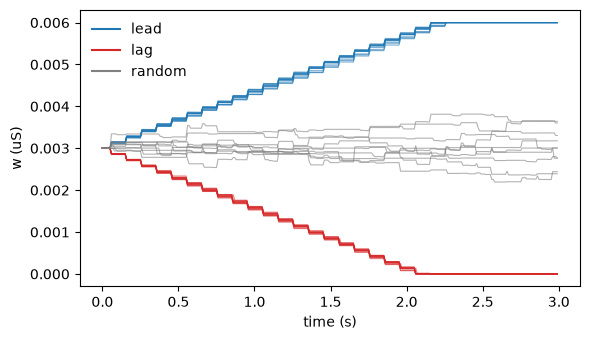

In [5]:
rng = np.random.default_rng(0)
duration = 3000.0
post_times = np.arange(50.0, duration, 100.0)
groups = {"lead": range(0, 10), "lag": range(10, 20), "random": range(20, 30)}
pre_times = []
for i in range(30):
    if i in groups["lead"]:
        t = post_times - 5.0 - rng.uniform(0.0, 5.0, post_times.size)
    elif i in groups["lag"]:
        t = post_times + 5.0 + rng.uniform(0.0, 5.0, post_times.size)
    else:
        t = np.sort(rng.uniform(0.0, duration, post_times.size))
    pre_times.append(np.round(t, 1) * u.ms)

traj_cell = braincell.Cell.point(1, V_init=-65.0 * u.mV)
traj_cell.place(mech.Synapse("ExpSyn", name="s", tau=2.0 * u.ms, e=0.0 * u.mV))
rule = mech.ConnectionRule(
    "PairSTDP",
    A_plus=0.0002 * u.uS,
    A_minus=0.00021 * u.uS,
    tau_plus=20.0 * u.ms,
    tau_minus=20.0 * u.ms,
    w_min=0.0 * u.uS,
    w_max=0.006 * u.uS,
    signals={"post": braincell.EventSequence.from_times((post_times * u.ms,))},
)
braincell.connect(
    "inputs",
    source=braincell.EventSequence.from_times(tuple(pre_times)),
    synapse=traj_cell.synapses["s"],
    weight=0.003 * u.uS,
    plasticity=rule,
)

traj_cell.connections["inputs"].record("w", "w", period=10.0 * u.ms)
samples = traj_cell.run(dt=0.1 * u.ms, duration=duration * u.ms).samples["w"]
times = samples.time.to_decimal(u.ms)
weights = samples.values.to_decimal(u.uS)

fig, ax = plt.subplots(figsize=(6, 3.5))
for (name, rows), color in zip(groups.items(), ("C0", "C3", "0.5")):
    ax.plot(np.asarray(times) / 1000.0, weights[:, list(rows)], color=color, lw=0.8, alpha=0.6)
    ax.plot([], [], color=color, label=name)
ax.set_xlabel("time (s)")
ax.set_ylabel("w (uS)")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

`reset_state()` starts the rule again from the rows' weight, and
`set(weight=...)` changes both that weight and the current one. A weight outside
`[w_min, w_max]` is rejected rather than clipped.

In [6]:
traj_cell.reset_state()
print("after reset_state:", traj_cell.connections["inputs"][:3].rule_state("w"))
traj_cell.connections["inputs"][:3].set(weight=0.001 * u.uS)
print("after set        :", traj_cell.connections["inputs"][:3].rule_state("w"))
try:
    traj_cell.connections["inputs"][:3].set(weight=0.01 * u.uS)
except ValueError as error:
    print("ValueError:", error)

after reset_state: [0.003 0.003 0.003] uS
after set        : [0.001 0.001 0.001] uS
ValueError: PairSTDP weight of 3 row(s) (first: row 0, 0.01 uS) is outside w_max=Quantity(0.006, "uS"); the rule rejects a weight outside its bounds rather than clipping it.


## 4. Live sources and delays

With a live source, such as another Cell's spikes, the rule runs in a
`Network`. A row's pre time is its *arrival*, after its delay. Below, one
presynaptic neuron fires once at about 10 ms and drives three postsynaptic
members through rows with delays of 0, 2 and 5 ms. A strong fixed input makes
every member fire at about 20 ms; their own spikes are the `post` events (no
`signals=`). The longer the delay, the closer the arrival to the post spike and
the larger the potentiation.

In [7]:
def hh_point(size):
    cell = braincell.Cell.point(size, V_init=-65.0 * u.mV, V_th=-20.0 * u.mV)
    cell.paint(
        mech.Ion("SodiumFixed", E=50.0 * u.mV),
        mech.Ion("PotassiumFixed", E=-77.0 * u.mV),
        mech.Channel("Na_HH1952", g_max=120.0 * u.mS / u.cm**2),
        mech.Channel("K_HH1952", g_max=36.0 * u.mS / u.cm**2),
        mech.Channel("IL", g_max=0.3 * u.mS / u.cm**2, E=-54.4 * u.mV),
    )
    return cell


pre_cell = hh_point(1)
pre_cell.place(mech.CurrentClamp(delay=10.0 * u.ms, durations=(1.0 * u.ms,), amplitudes=(0.5 * u.nA,)))
post_cell = hh_point(3)
post_cell.place(mech.Synapse("ExpSyn", name="exc", tau=2.0 * u.ms, e=0.0 * u.mV))

net = braincell.Network("live_stdp")
pre_pop = net.add_population("pre", pre_cell)
post_pop = net.add_population("post", post_cell)
drive = net.add_population("drive", braincell.EventSequence.from_times(([20.0] * u.ms,)))
net.connect("drive", source=drive.event_outputs["event"], synapse=post_pop.synapses["exc"], weight=0.05 * u.uS)

delays = [0.0, 2.0, 5.0] * u.ms
rule = mech.ConnectionRule(
    "PairSTDP", A_plus=0.01 * u.uS, A_minus=0.0105 * u.uS, tau_plus=20.0 * u.ms, tau_minus=20.0 * u.ms
)
net.connect(
    "plastic",
    source=pre_pop.event_outputs["spike"],
    synapse=post_pop.synapses["exc"],
    weight=0.0001 * u.uS,
    delay=delays,
    plasticity=rule,
)
dt = 0.025 * u.ms
result = net.run(dt=dt, duration=40.0 * u.ms)

pre_spike = result.events["pre"]["spike"].time
post_spike = result.events["post"]["spike"].time
print("pre spike at:", pre_spike)
print("post spikes at:", post_spike)
print("dw:", post_cell.connections["plastic"].rule_state("w") - 0.0001 * u.uS)

pre spike at: [10.3] ms
post spikes at: [20.1 20.1 20.1] ms
dw: [0.00612626 0.00677057 0.00786628] uS


A spike detected in the step from $t_m$ to $t_{m+1}$ is an event at
$t_{m+1} = t_m + dt$, the time `result.events` reports, as NEURON's
`NetCon.record`. With a delay of $k$ steps it arrives at $t_{m+1+k}$: the
reported time plus the delay. The rule pairs the arrival with the post spike's
reported time; the reference below uses those times.

In [8]:
t_pre = float(pre_spike.to_decimal(u.ms)[0])
t_post = post_spike.to_decimal(u.ms)
arrival = t_pre + delays.to_decimal(u.ms)
print("reference dw (uS):", 0.01 * np.exp(-(t_post - arrival) / 20.0))

reference dw (uS): [0.00612626 0.00677057 0.00786628]


A standalone `Cell.run` delivers live events on another schedule, so it
rejects a rule on a live source and points to `Network`; scheduled sources,
as in sections 1–3, work in both.

In [9]:
lone = braincell.Cell.point(1, V_init=-65.0 * u.mV)
lone.place(mech.Synapse("ExpSyn", name="s"))
braincell.connect(
    "self", source=lone.event_outputs["spike"], synapse=lone.synapses["s"], weight=0.001 * u.uS, delay=1.0 * u.ms, plasticity=rule
)
try:
    lone.run(dt=0.1 * u.ms, duration=1.0 * u.ms)
except NotImplementedError as error:
    print("NotImplementedError:", error)

NotImplementedError: Connection 'self' has a plasticity rule on a live source, which runs only in a braincell.Network: a standalone Cell.run delivers live events on another schedule. Add the Cells to a Network and run that, or connect a scheduled source (EventSequence, NetStim).


## 5. Short-term depression inside the synapse

A connection rule changes the weight of a row. Short-term depression is
different: it depletes a resource of the synapse itself, shared by every row
connected to it. `braincell.synapse.ExpSynSTD` is an `ExpSyn` with the
Tsodyks–Markram resource $x$, which starts at 1 and recovers with
$\tau_\mathrm{rec}$. An event of weight $w$ releases the fraction $U$ of what
is left:

$$g \leftarrow g + w\,U\,x, \qquad x \leftarrow x\,(1 - U).$$

Ten events at 20 Hz, with $U = 0.5$ and $\tau_\mathrm{rec} = 800$ ms, shrink
from one to the next, while `ExpSyn` gives the same response to each. Between
events $x$ recovers as $1 - (1 - x)\,e^{-\Delta t/\tau_\mathrm{rec}}$.

simulated: [1.       0.530293 0.309669 0.206041 0.157366 0.134503 0.123764 0.11872
 0.11635  0.115237]
reference: [1.       0.530293 0.309669 0.206041 0.157366 0.134503 0.123764 0.11872
 0.11635  0.115237]


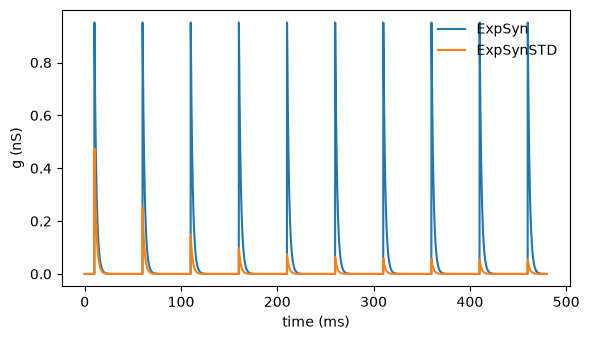

In [10]:
train = 10.0 + 50.0 * np.arange(10)  # ms
traces = {}
for model, extra in (("ExpSyn", {}), ("ExpSynSTD", dict(U=0.5, tau_rec=800.0 * u.ms))):
    c = braincell.Cell.point(1, V_init=-65.0 * u.mV)
    c.paint(mech.Channel("IL", g_max=0.1 * u.mS / u.cm**2, E=-65.0 * u.mV))
    c.place(mech.Synapse(model, name="s", tau=2.0 * u.ms, e=0.0 * u.mV, **extra))
    braincell.connect(
        "train",
        source=braincell.EventSequence.from_times((train * u.ms,)),
        synapse=c.synapses["s"],
        weight=0.001 * u.uS,
    )
    c.record("g", braincell.observe.synapse(name="s").state("g"))
    result = c.run(dt=0.1 * u.ms, duration=480.0 * u.ms)
    traces[model] = (result.time.to_decimal(u.ms), result.samples["g"].values.to_decimal(u.uS)[:, 0])

# The sample one step after each event, relative to the first.
after = np.round(train / 0.1).astype(int) + 1
x_ref = [1.0]
for _ in train[1:]:
    x_ref.append(1.0 - (1.0 - 0.5 * x_ref[-1]) * np.exp(-50.0 / 800.0))
print("simulated:", np.round(traces["ExpSynSTD"][1][after] / traces["ExpSynSTD"][1][after[0]], 6))
print("reference:", np.round(x_ref, 6))

fig, ax = plt.subplots(figsize=(6, 3.5))
for model, (t, g) in traces.items():
    ax.plot(t, g * 1e3, label=model)
ax.set_xlabel("time (ms)")
ax.set_ylabel("g (nS)")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

`ExpSynSTD` declares `ScalarEventInput(u.uS, aggregation="sum_count")`: on
each boundary a synapse receives the summed weight $W$ of its events *and*
their number $K$, from every kind of source and delay. The events of one
boundary have no order, so $K$ events release what $K$ events in a row would:

$$\Delta g = \frac{W}{K}\,x\,\bigl(1 - (1 - U)^K\bigr), \qquad x \leftarrow x\,(1 - U)^K.$$

Two 1 nS rows that fire together add $0.5 + 0.25 = 0.75$ nS and leave
$x = 0.25$; with `ExpSyn` they would add 2 nS.

In [11]:
pair = braincell.Cell.point(1, V_init=-65.0 * u.mV)
pair.place(mech.Synapse("ExpSynSTD", name="s", tau=2.0 * u.ms, e=-65.0 * u.mV, U=0.5))
braincell.connect(
    "pair",
    source=braincell.EventSequence.from_times(([1.0] * u.ms, [1.0] * u.ms)),
    synapse=pair.synapses["s"][[0, 0]],
    weight=0.001 * u.uS,
)
pair.record("g", braincell.observe.synapse(name="s").state("g"))
pair.record("x", braincell.observe.synapse(name="s").state("x"))
result = pair.run(dt=0.1 * u.ms, duration=1.2 * u.ms)
g = result.samples["g"].values.to_decimal(u.uS)[:, 0]
x = result.samples["x"].values[:, 0]
# The last sample, at 1.1 ms, is 0.1 ms after the events: g has decayed by exp(-0.1 / tau).
# Rounded: in that 0.1 ms the solver's decay of g and the recovery of x are not exact.
print("released:", round(float(g[-1] * np.exp(0.1 / 2.0)) * 1e3, 3), "nS")
print("x after :", round(float(x[-1]), 3))

released: 0.75 nS
x after : 0.25


A connection rule and a release model combine: the event a row with a rule
delivers carries the row's current weight, and the synapse multiplies it by
the released fraction. Each placed synapse has its own resource; rows that
share a synapse share it, while their weights and rule states stay their own.

## 6. Facilitation and depression

`braincell.synapse.ExpSynSTP` adds the Tsodyks–Markram release fraction $u$ to
`ExpSynSTD`. $u$ rests at 0 and decays with $\tau_\mathrm{fac}$; $x$ recovers
with $\tau_\mathrm{rec}$ as before. An event first raises $u$, then releases the
fraction $u$ of what is left:

$$u \leftarrow u + U\,(1 - u), \qquad g \leftarrow g + w\,u\,x, \qquad x \leftarrow x\,(1 - u).$$

After a long rest an event releases $U\,x$, as in `ExpSynSTD`. Facilitation
needs $\tau_\mathrm{fac} > 0$: the default $\tau_\mathrm{fac} = 0$ turns it
off. Below is the facilitating parameter set of NEST's `tsodyks2_synapse`
example ($U = 0.1$, $\tau_\mathrm{fac} = 1$ s, $\tau_\mathrm{rec} = 100$ ms):
eight events at 50 Hz, then one after a 500 ms pause. With depression alone
each event adds less than the one before; with facilitation the increments
first grow, and after the pause $x$ has recovered while $u$ has not yet
decayed. The reference is NEST's event-by-event rule (Maass & Markram 2002,
Eqs. 4–5), which gives the same increments. `exp_euler` integrates these
linear relaxations exactly.

ExpSynSTD simulated: [0.1      0.091813 0.08578  0.081334 0.078059 0.075645 0.073867 0.072556
 0.099766]
ExpSynSTD reference: [0.1      0.091813 0.08578  0.081334 0.078059 0.075645 0.073867 0.072556
 0.099766]
ExpSynSTP simulated: [0.1      0.172808 0.210568 0.219857 0.213077 0.201093 0.190181 0.182502
 0.391125]
ExpSynSTP reference: [0.1      0.172808 0.210568 0.219857 0.213077 0.201093 0.190181 0.182502
 0.391125]


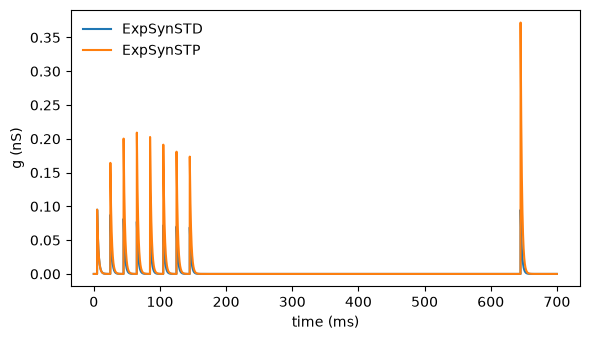

In [12]:
train = np.concatenate([5.0 + 20.0 * np.arange(8), [645.0]])  # ms
dt_ms, tau_ms = 0.1, 2.0
steps = np.round(train / dt_ms).astype(int)
traces, jumps = {}, {}
for model, extra in (
    ("ExpSynSTD", dict(U=0.1, tau_rec=100.0 * u.ms)),
    ("ExpSynSTP", dict(U=0.1, tau_fac=1000.0 * u.ms, tau_rec=100.0 * u.ms)),
):
    c = braincell.Cell.point(1, V_init=-65.0 * u.mV, solver="exp_euler")
    c.paint(mech.Channel("IL", g_max=0.1 * u.mS / u.cm**2, E=-65.0 * u.mV))
    c.place(mech.Synapse(model, name="s", tau=tau_ms * u.ms, e=0.0 * u.mV, **extra))
    braincell.connect(
        "train",
        source=braincell.EventSequence.from_times((train * u.ms,)),
        synapse=c.synapses["s"],
        weight=0.001 * u.uS,
    )
    c.record("g", braincell.observe.synapse(name="s").state("g"))
    result = c.run(dt=dt_ms * u.ms, duration=700.0 * u.ms)
    g = result.samples["g"].values.to_decimal(u.uS)[:, 0]
    traces[model] = (result.time.to_decimal(u.ms), g)
    # The jump of g on each event's boundary, per unit weight; g decays by exp(-dt/tau) over the step.
    jumps[model] = (g[steps + 1] * np.exp(dt_ms / tau_ms) - g[steps]) / 0.001


def tsodyks2(times, U, tau_fac, tau_rec):
    """Each event's x u by NEST's tsodyks2_synapse rule (Maass & Markram 2002, Eqs. 4-5)."""
    x, u_, out = 1.0, U, []
    for k in range(len(times)):
        if k:
            h = times[k] - times[k - 1]
            x = 1.0 + (x - x * u_ - 1.0) * np.exp(-h / tau_rec)
            u_ = U + u_ * (1.0 - U) * (np.exp(-h / tau_fac) if tau_fac else 0.0)
        out.append(x * u_)
    return np.array(out)


for model, tau_fac in (("ExpSynSTD", 0.0), ("ExpSynSTP", 1000.0)):
    print(f"{model} simulated:", np.round(jumps[model], 6))
    print(f"{model} reference:", np.round(tsodyks2(train, 0.1, tau_fac, 100.0), 6))

fig, ax = plt.subplots(figsize=(6, 3.5))
for model, (t, g) in traces.items():
    ax.plot(t, g * 1e3, label=model)
ax.set_xlabel("time (ms)")
ax.set_ylabel("g (nS)")
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

On one boundary, $K$ events from $u_0$ and $x_0$ release what $K$ events in a
row would: the $j$-th uses $u_j = 1 - (1 - u_0)(1 - U)^j$, so

$$x_K = x_0\,(1 - u_0)^K\,(1 - U)^{K(K+1)/2}, \qquad \Delta g = \frac{W}{K}\,(x_0 - x_K).$$

With $U = 0.25$ from rest, two 1 nS rows that fire together release
$0.25 + 0.75 \cdot 0.4375 = 0.578125$ of the resource. With
$\tau_\mathrm{fac} = 0$ each event uses $U$, as in `ExpSynSTD`:
$0.25 + 0.75 \cdot 0.25 = 0.4375$. (This is not the limit of a small
$\tau_\mathrm{fac}$: events on one boundary have no time to decay, so with any
$\tau_\mathrm{fac} > 0$ they facilitate each other.)

In [13]:
for label, extra in (("tau_fac = 100 ms", dict(tau_fac=100.0 * u.ms)), ("tau_fac = 0     ", {})):
    pair = braincell.Cell.point(1, V_init=-65.0 * u.mV, solver="exp_euler")
    pair.place(mech.Synapse("ExpSynSTP", name="s", tau=2.0 * u.ms, e=-65.0 * u.mV, U=0.25, **extra))
    braincell.connect(
        "pair",
        source=braincell.EventSequence.from_times(([1.0] * u.ms, [1.0] * u.ms)),
        synapse=pair.synapses["s"][[0, 0]],
        weight=0.001 * u.uS,
    )
    pair.record("g", braincell.observe.synapse(name="s").state("g"))
    g = pair.run(dt=0.1 * u.ms, duration=1.2 * u.ms).samples["g"].values.to_decimal(u.uS)[:, 0]
    # The sample at 1.1 ms is one step after the events; g has decayed by exp(-0.1 / tau).
    print(f"{label}: released {round(float(g[11] * np.exp(0.1 / 2.0)) * 1e3, 6)} nS")

tau_fac = 100 ms: released 0.578125 nS


tau_fac = 0     : released 0.4375 nS


## Notes

- One rule covers every row of its `connect` call; rows without a rule are
  unchanged. Each call with a rule has its own state.
- The rule state lives on the target Cell, in its state tree, and the dynamic
  weight starts from the rows' weight at `init_state` and `reset_state`. A
  trainable bound to the rows' weight (`trainable(weight=...)`) therefore stays
  differentiable through the rule.
- A new rule subclasses `braincell.ConnectionRule` and is registered with
  `braincell.mech.register_connection_rule`; see the API reference.